# Camera calibration using CHARUCO

## Libraries used 
We need to import the following libraries.

This notebook works with OpenCV 4.7 or newer, including OpenCV 5. Apart from `opencv-contrib-python` (see the Moodle book) it needs Jupyter, matplotlib and Pillow. If they are missing, install them from a terminal with:

`pip install ipykernel matplotlib pillow`

In [3]:
import numpy as np       #Maths library
import cv2               #openCV
from PIL import Image    #Library for Image file manipulation
import os                #To access files and folders
from pathlib import Path    #To handle file paths
from cv2 import aruco    #ArUco main library
import math

# Library to Print nice graphs
#from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import matplotlib as mpl
%matplotlib inline


Matplotlib is building the font cache; this may take a moment.


### Create the CHARUCO chessboard

First, we create the board in a folder called workdir. The result will be a tiff image.

In [4]:
# Get the notebook's directory
notebook_path = Path().resolve()
# If the last part of the path is workdir, move up until you are not in workdir
while notebook_path.name == "workdir":
    notebook_path = notebook_path.parent

print(f"Notebook is located at: {notebook_path}")

# Create the folders workdir and workdir/images if they do not exist
workdir = os.path.join(notebook_path, "workdir")

if not os.path.exists(workdir):
    print(f"Directory {workdir} created.")
else:
    print(f"Directory {workdir} already exists.")

os.makedirs(os.path.join(workdir, "images"), exist_ok=True)

os.chdir(workdir)

print("We are working on directory: ", os.getcwd())

Notebook is located at: /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates
Directory /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir created.
We are working on directory:  /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir


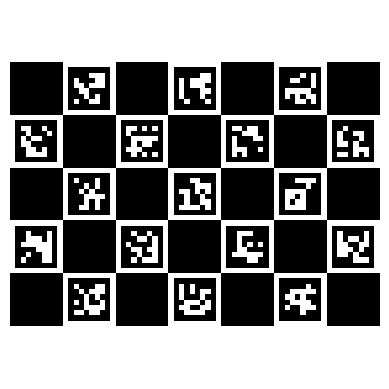

In [5]:

# Load the dictionary of ArUco for 6x6
aruco_dict = aruco.getPredefinedDictionary(aruco.DICT_6X6_250)

# Create the board, draw it, and save it in the folder
board = aruco.CharucoBoard((7, 5), 1, 0.8, aruco_dict)
imboard = board.generateImage((2000, 2000))
cv2.imwrite(os.path.join(workdir, "chessboard.tiff"), imboard)

#Create a figure with a subplot and plot it below for an inspection of the ChAruco board (we are using various settings)
fig = plt.figure()
ax = fig.add_subplot(1,1,1)
plt.imshow(imboard, cmap = mpl.cm.gray, interpolation = "nearest")
ax.axis("off")
plt.show()


You need to <font color='red'>print</font> the board.

Stick the board on a rigid surface, e.g. an A4 notepad, and <font color='red'>take photos</font> from multiple angles (>=20) with the camera you want to calibrate.

Save them in the folder workdir/images (jpg, jpeg or png files; if your phone saves HEIC photos, convert them to jpg first).

### Use the board to calibrate the camera
The next piece of code will list all the images in the workdir/images folder

In [7]:
datadir = os.path.join(workdir, "images")
images = sorted(
    os.path.join(datadir, f)
    for f in os.listdir(datadir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
)
print(f"Found {len(images)} images in {datadir}")
if len(images) == 0:
    raise FileNotFoundError(f"No jpg or png images found in {datadir}. Save your photos there and run this cell again.")
images

Found 24 images in /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images


['/Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0001.jpg',
 '/Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0002.jpg',
 '/Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0003.jpg',
 '/Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0004.jpg',
 '/Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0005.jpg',
 '/Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0006.jpg',
 '/Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0007.jpg',
 '/Use

We are going to print the images to see what you have got. Check that all images show the board

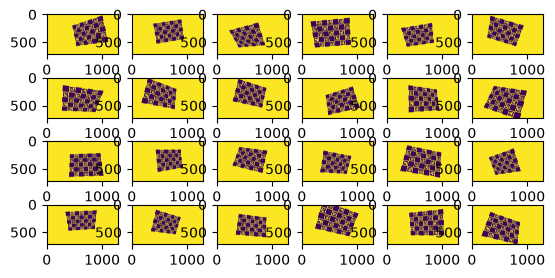

In [8]:
plotsize=round(math.sqrt(len(images)))+1
fig = plt.figure()
t=1
for an_im in images:
    try:
        im = Image.open(an_im)
    except Exception:
        print(f"Could not open {an_im}: remove it from the images folder")
        continue
    ax = fig.add_subplot(plotsize,plotsize,t)
    t+=1
    plt.imshow(im)


Zoom to the first image (index:0)

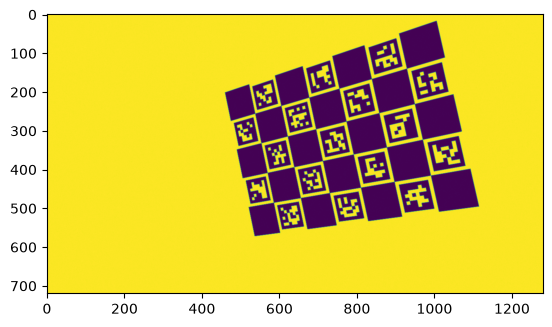

In [9]:
im = Image.open(images[0])
fig = plt.figure()
ax = fig.add_subplot(1,1,1)
plt.imshow(im)
#ax.axis('off')
plt.show()

Now, the camera calibration can be done using all the images of the chessboard. Two functions are necessary:

* The first (read_chessboards) will detect the corners of the board on all the images.
* The second (calibrate_camera) will process the detected corners to estimate the camera calibration data.

The code below is the definition of the function to read the chessboard

In [10]:
# The detector finds the ArUco markers and the corners of the ChArUco board in one step
charuco_detector = aruco.CharucoDetector(board)

def read_chessboards(images):
    """
    Detects the corners of the ChArUco board in all the images.
    """
    print("DETECTION STARTS:")
    allCorners = []
    allIds = []
    imsize = None

    for im in images:
        print("=> Processing image {0}".format(im))
        frame = cv2.imread(im)
        if frame is None:
            print("   Could not read this image, skipping it")
            continue
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        imsize = (gray.shape[1], gray.shape[0])   # (width, height), the order OpenCV expects

        corners, ids, markerCorners, markerIds = charuco_detector.detectBoard(gray)

        # Use the image only if enough corners of the board are visible
        if ids is not None and len(ids) > 3:
            allCorners.append(corners)
            allIds.append(ids)
        else:
            print("   The board was not found in this image, skipping it")

    return allCorners, allIds, imsize

The line below calls the above function for all images and saves the results in allCorners, allIds

In [11]:
allCorners,allIds,imsize=read_chessboards(images)

print(f"The board was found in {len(allCorners)} of {len(images)} images")
if len(allCorners) == 0:
    raise RuntimeError("The board was not found in any image. Check that the photos show the whole board.")
if len(allCorners) < 10:
    print("WARNING: very few usable images. Take more photos from different angles (20 or more).")

DETECTION STARTS:
=> Processing image /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0001.jpg
=> Processing image /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0002.jpg
=> Processing image /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0003.jpg
=> Processing image /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0004.jpg
=> Processing image /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0005.jpg
=> Processing image /Users/ioannisgeorgilas/Library/CloudStorage/OneDrive-UniversityofBath/Teaching/ME32088/CodeBase/CV_Templates/workdir/images/IMG_0006.jpg
=> Processing image /Users/ioannis

And this is the definition of the function that performs the calibration

In [12]:
def calibrate_camera(allCorners,allIds,imsize):   
    """
    Calibrates the camera using the detected corners.
    """
    print("CAMERA CALIBRATION")

    # For every image, match the detected corners with their 3D position on the board
    objPoints = []
    imgPoints = []
    for corners, ids in zip(allCorners, allIds):
        obj, img = board.matchImagePoints(corners, ids)
        objPoints.append(obj)
        imgPoints.append(img)

    # Initial guess: focal length 1000 pixels and the principal point in the centre of the image
    # (imsize is (width, height))
    cameraMatrixInit = np.array([[ 1000.,    0., imsize[0]/2.],
                                 [    0., 1000., imsize[1]/2.],
                                 [    0.,    0.,           1.]])

    distCoeffsInit = np.zeros((5,1))
    flags = (cv2.CALIB_USE_INTRINSIC_GUESS + cv2.CALIB_FIX_ASPECT_RATIO) 
    (ret, camera_matrix, distortion_coefficients0, 
     rotation_vectors, translation_vectors,
     stdDeviationsIntrinsics, stdDeviationsExtrinsics, 
     perViewErrors) = cv2.calibrateCameraExtended(
                      objectPoints=objPoints,
                      imagePoints=imgPoints,
                      imageSize=imsize,
                      cameraMatrix=cameraMatrixInit,
                      distCoeffs=distCoeffsInit,
                      flags=flags,
                      criteria=(cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_COUNT, 10000, 1e-9))

    return ret, camera_matrix, distortion_coefficients0, rotation_vectors, translation_vectors

Now we run the calibration function and get back a number of variables.

ret: is the reprojection error obtained from the calibration (the smaller the better)
CM : is the camera matrix to pass to the pose estimation
dist_coef: is the distortion coefficient matrix to pass to the pose estimation
rvecs, tvecs: are the rotation and translation vectors of the board relative to the camera, one pair for each image.

(Note: By executing the function with %time in the beginning we are going to get the duration this command will take)

In [13]:
%time ret, CM, dist_coef, rvecs, tvecs = calibrate_camera(allCorners,allIds,imsize)

CAMERA CALIBRATION
CPU times: user 16.9 ms, sys: 6.95 ms, total: 23.9 ms
Wall time: 22.8 ms


### Check calibration results

First let's look at the different coefficients we have obtained and assess the quality of the calibration

In [14]:
print(f"Reprojection error: {ret:.3f} pixels")
# Good calibration: < 0.5 pixels
# Acceptable: 0.5-1.0 pixels  
# Poor: > 1.0 pixels


Reprojection error: 0.151 pixels


In [15]:
print("Distortion coefficients:")
print(f"k1={dist_coef[0][0]:.4f}, k2={dist_coef[1][0]:.4f}, p1={dist_coef[2][0]:.4f}")
print(f"p2={dist_coef[3][0]:.4f}, k3={dist_coef[4][0]:.4f}")
# k1, k2 and k3 describe the radial distortion (straight lines bending outwards or inwards),
# p1 and p2 the tangential distortion. The closer to zero, the less distortion.
# If the values look extreme, check the reprojection error and the photos


Distortion coefficients:
k1=-0.0027, k2=0.0448, p1=-0.0002
p2=-0.0000, k3=-0.2385


Finally, let's see two outputs of the calibration and evaluate them visually

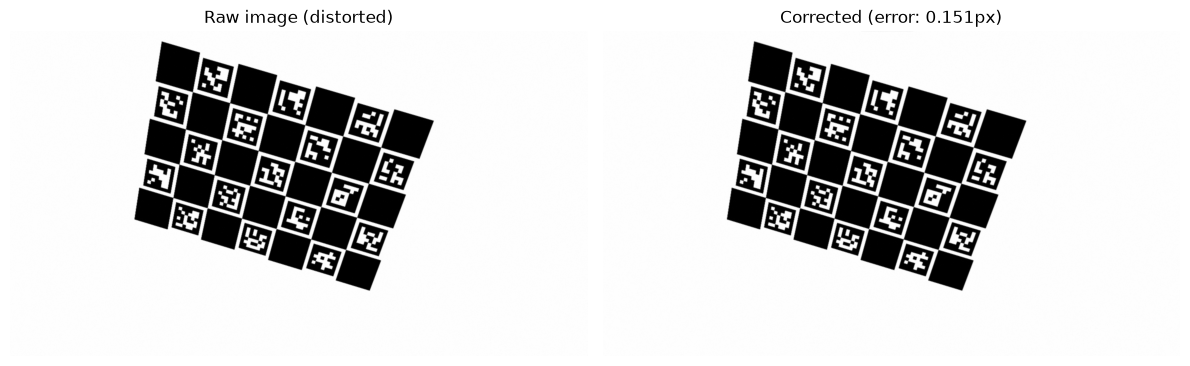

In [16]:
# Compare one of the photos (here the 6th, or the last one if you have fewer) with its corrected version
i = min(5, len(images) - 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
frame = cv2.imread(images[i])
img_undist = cv2.undistort(frame, CM, dist_coef, None)

axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Raw image (distorted)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(img_undist, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Corrected (error: {ret:.3f}px)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Save the Camera Matrix and the distortion Coefficient using numpy

Finally, we save the CM and dist_coef in a npz file for later use. The file is saved in the workdir folder (copy it next to your Python script to use it). We can change the name to include an indication of the camera this information refers to.

In [17]:
np.savez('Calibration.npz', CM=CM, dist_coef=dist_coef)


Finally, we load the variables from the file and compare them to the ones we calculated earlier to ensure everything is correct.

In [18]:
CM_test, dist_coef_test = np.load('Calibration.npz')['CM'], np.load('Calibration.npz')['dist_coef']

assert np.array_equal(CM, CM_test), "Camera Matrix does not match!"
assert np.array_equal(dist_coef, dist_coef_test), "Distortion Coefficients do not match!"

# If no assertion error is raised, the saved and loaded values match